Análise dos dados para tratamento estatístico

In [1]:
import pandas as pd
import geopandas as gpd

path = '/home/vinicius/projects/projects/gee-data-pipeline/saidas/subbacias_corrigidas_com_gcn.geojson'

gdf = gpd.read_file(path)
gdf['gcn'] = gdf['gcn'].clip(lower=0, upper=100)

gdf.describe()


,centroid_x,centroid_y,area_sqkm,latitude,longitude,basinid,raster_val,gcn
count,60.000000,6.000000e+01,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,677402.482872,7.565442e+06,946.058851,-22.001409,-43.287620,29.500000,30.500000,81.600749
std,139798.122885,7.977360e+04,731.941234,0.728904,1.351052,17.464249,17.464249,1.405939
min,384476.569360,7.405612e+06,0.587255,-23.458104,-46.130000,0.000000,1.000000,78.628804
25%,592063.651053,7.510093e+06,279.213049,-22.511052,-44.104273,14.750000,15.750000,80.393840
50%,695005.684053,7.570819e+06,862.252863,-21.951911,-43.111868,29.500000,30.500000,81.870364
75%,797169.482168,7.619248e+06,1310.780790,-21.506954,-42.146239,44.250000,45.250000,82.784025
max,892258.566422,7.717218e+06,2501.500641,-20.620799,-41.212032,59.000000,60.000000,83.881437


In [2]:
gdf.nlargest(5, 'gcn')

,name,centroid_x,centroid_y,area_sqkm,latitude,longitude,basinid,raster_val,gcn,geometry
41,Subbasin-42,800672.229856,7.615418e+06,304.140783,-21.538835,-42.097305,41,42,83.881437,"POLYGON ((-42.00986 -21.42782, -42.00899 -21.4..."
33,Subbasin-34,824138.135231,7.598911e+06,164.765694,-21.683661,-41.867805,33,34,83.680266,"POLYGON ((-41.79808 -21.5975, -41.79721 -21.59..."
54,Subbasin-55,761322.818006,7.594186e+06,2479.731440,-21.736660,-42.473551,54,55,83.660859,"POLYGON ((-42.57327 -21.53153, -42.57153 -21.5..."
51,Subbasin-52,681320.971017,7.553944e+06,157.188478,-22.110061,-43.242208,51,52,83.542138,"POLYGON ((-43.34401 -22.04915, -43.34314 -22.0..."
30,Subbasin-31,761679.888500,7.626831e+06,2386.357960,-21.441943,-42.475218,30,31,83.432242,"POLYGON ((-42.75521 -21.20297, -42.75173 -21.2..."


In [3]:
gdf.nsmallest(5, 'gcn')

,name,centroid_x,centroid_y,area_sqkm,latitude,longitude,basinid,raster_val,gcn,geometry
16,Subbasin-17,385272.487324,7.441211e+06,1309.455389,-23.133950,-46.120554,16,17,78.628804,"MULTIPOLYGON (((-46.02879 -23.19474, -46.03144..."
59,Subbasin-60,892258.566422,7.605215e+06,1139.461498,-21.613106,-41.212032,59,60,78.954552,"POLYGON ((-41.3657 -21.3947, -41.36483 -21.394..."
17,Subbasin-18,465695.033389,7.411055e+06,1376.891791,-23.409974,-45.335764,17,18,78.956187,"MULTIPOLYGON (((-45.59912 -23.41233, -45.59824..."
46,Subbasin-47,540189.645854,7.503376e+06,381.054821,-22.575884,-44.609048,46,47,79.169113,"POLYGON ((-44.65069 -22.36148, -44.64894 -22.3..."
36,Subbasin-37,432451.813358,7.405612e+06,189.397761,-23.458104,-45.661368,36,37,79.239407,"POLYGON ((-45.66254 -23.36639, -45.66077 -23.3..."


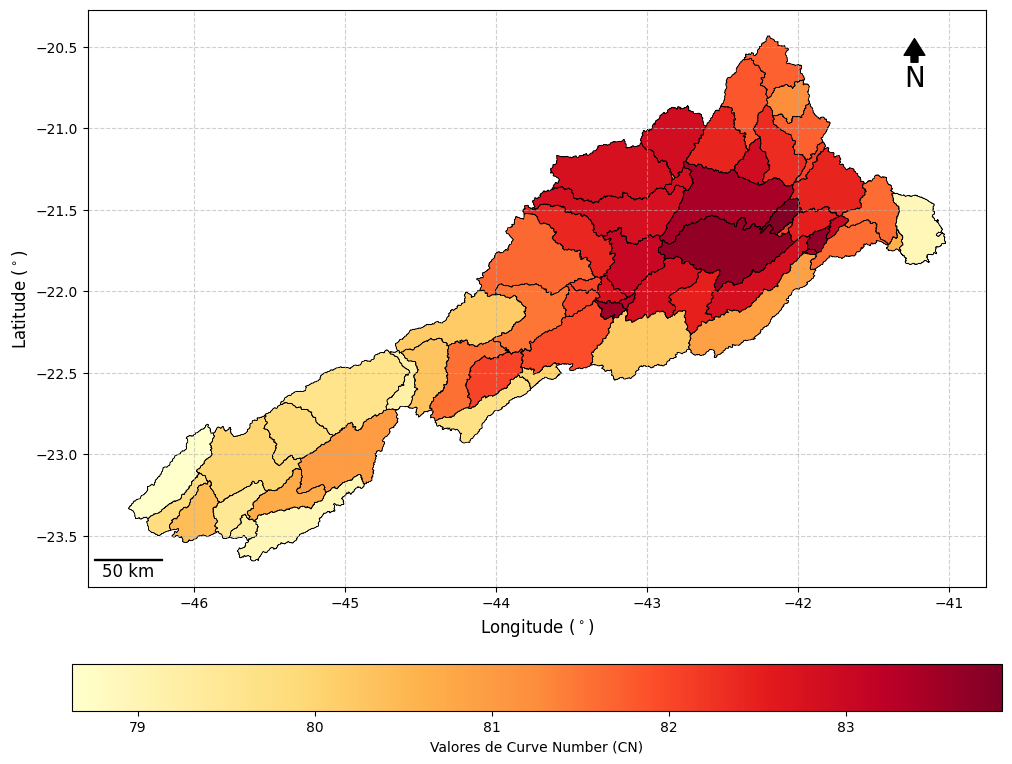

In [2]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
import os

output_dir = "/home/vinicius/projects/projects/gee-data-pipeline/saidas/graphs"
os.makedirs(output_dir, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 10))

# 2. Plotar o GeoJSON usando o eixo 'ax' criado acima
# O 'clip' garante que o 100.92 seja visualizado como 100 na legenda
gdf.plot(ax=ax,
         column='gcn',
         cmap='YlOrRd',
         legend=True,
         edgecolor='black', # Adiciona bordas finas entre as sub-bacias
         linewidth=0.5,
         legend_kwds={'label': "Valores de Curve Number (CN)", 'orientation': "horizontal", 'pad': 0.1})

# 3. Adicionar e configurar os eixos
ax.set_xlabel(r'Longitude ($^\circ$)', fontsize=12)
ax.set_ylabel(r'Latitude ($^\circ$)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)

x, y, arrow_length = 0.92, 0.95, 0.07
ax.annotate(
    'N', xy=(x, y), xytext=(x, y - arrow_length),
    arrowprops=dict(facecolor='black', width=5, headwidth=15),
    ha='center', va='center', fontsize=20,
    xycoords=ax.transAxes
)


# Configuração da barra: 0.45 graus aprox 50km na latitude da BHRPS
fontprops = fm.FontProperties(size=12)
scalebar = AnchoredSizeBar(ax.transData,
                           0.45, '50 km', 'lower left',
                           pad=0.3,
                           color='black',
                           frameon=False,
                           size_vertical=0.005,
                           fontproperties=fontprops)

ax.add_artist(scalebar)

caminho_salvamento = os.path.join(output_dir, 'mapa_gcn_final.png')
plt.savefig(caminho_salvamento, dpi=300, bbox_inches='tight')

plt.show()

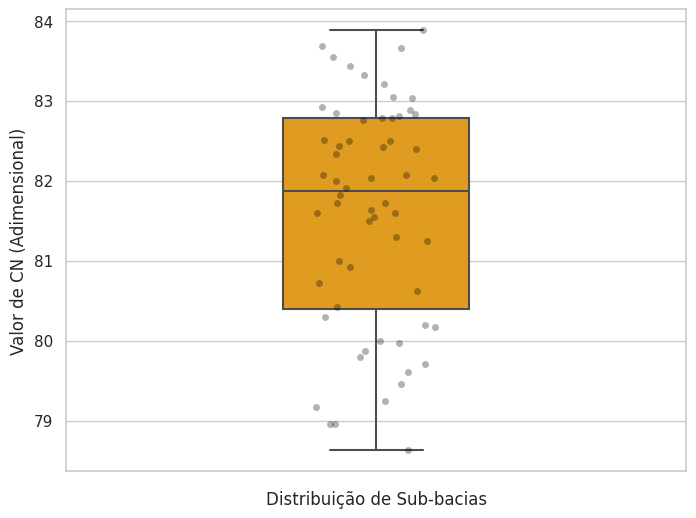

In [12]:
import seaborn as sns

# Configuração do estilo acadêmico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 6))

# Criando o Boxplot
sns.boxplot(y=gdf['gcn'],
            color='orange',
            width=0.3,
            linewidth=1.5,
            flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 8})

# Opcional: Adicionar os pontos (sub-bacias) sobre o boxplot para mostrar a densidade
sns.stripplot(y=gdf['gcn'], color='black', alpha=0.3, jitter=True)

# Configurações de eixos e títulos

ax.set_ylabel('Valor de CN (Adimensional)', fontsize=12)
ax.set_xlabel('Distribuição de Sub-bacias', fontsize=12)

# Salvar para o Overleaf

caminho_salvamento = os.path.join(output_dir, 'boxplot_gcn_tcc.png')
plt.savefig(caminho_salvamento, dpi=300, bbox_inches='tight')
plt.show()

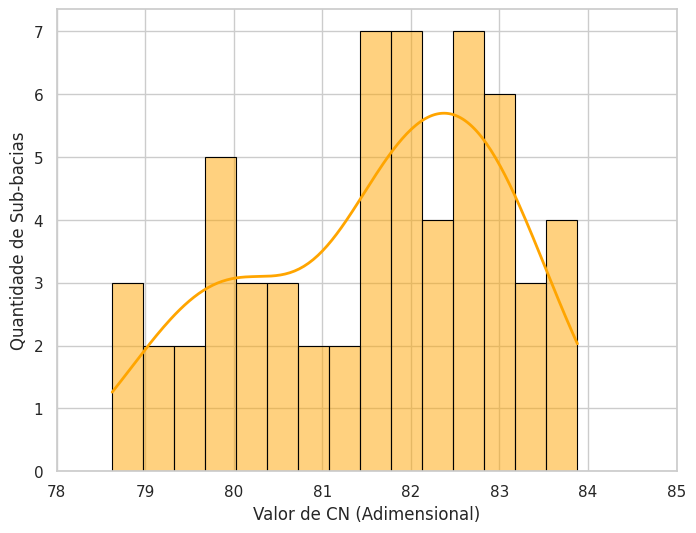

In [ ]:
import seaborn as sns

# Configuração do estilo acadêmico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 6))

# Criando o Histograma com a linha de densidade (KDE)
sns.histplot(x=gdf['gcn'],
             kde=True,
             color='orange',
             bins=15,  # Define a quantidade de faixas (barras)
             edgecolor='black',
             linewidth=0.8,
             line_kws={"linewidth": 2}) # Espessura da linha de densidade


ax.set_xlabel('Valor de CN (Adimensional)', fontsize=12)
ax.set_ylabel('Quantidade de Sub-bacias', fontsize=12)
ax.set_xlim(78, 85)

# Salvar para o Overleaf em alta resolução (300 DPI)
caminho_salvamento = os.path.join(output_dir, 'histograma_gcn_tcc.png')
plt.savefig(caminho_salvamento, dpi=300, bbox_inches='tight')
plt.show()

In [7]:
# 1. Obter estatísticas básicas
stats = gdf['gcn'].describe()

# 2. Calcular o Coeficiente de Variação (CV) em porcentagem
cv = (stats['std'] / stats['mean']) * 100

# 3. Mostrar os resultados formatados para a sua tabela
print("-" * 30)
print("ESTATÍSTICAS PARA O TCC")
print("-" * 30)
print(f"Contagem: {int(stats['count'])}")
print(f"Média: {stats['mean']:.2f}")
print(f"Desvio Padrão: {stats['std']:.2f}")
print(f"CV: {cv:.2f}%")
print(f"Mínimo: {stats['min']:.2f}")
print(f"25% (Q1): {stats['25%']:.2f}")
print(f"50% (Mediana): {stats['50%']:.2f}")
print(f"75% (Q3): {stats['75%']:.2f}")
print(f"Máximo: {stats['max']:.2f}")
print("-" * 30)

------------------------------
ESTATÍSTICAS PARA O TCC
------------------------------
Contagem: 60
Média: 81.60
Desvio Padrão: 1.41
CV: 1.72%
Mínimo: 78.63
25% (Q1): 80.39
50% (Mediana): 81.87
75% (Q3): 82.78
Máximo: 83.88
------------------------------


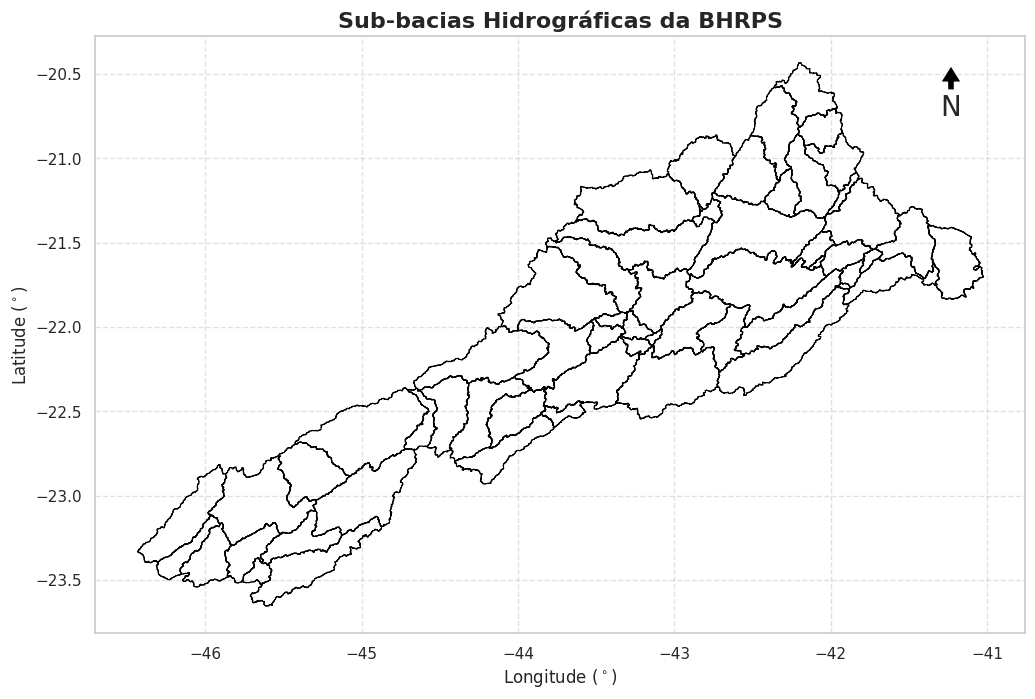

In [8]:
import os
import matplotlib.pyplot as plt

output_dir = "/home/vinicius/projects/projects/gee-data-pipeline/saidas/graphs"
os.makedirs(output_dir, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 10))

# 1. Plotar apenas a geometria das sub-bacias
gdf.plot(
    ax=ax,
    facecolor='none',      # Mantenha 'none' para transparente ou use uma cor única (ex: '#e0e0e0')
    edgecolor='black',     # Limites das sub-bacias
    linewidth=0.8
)

# 2. Configuração dos eixos e título
ax.set_title('Sub-bacias Hidrográficas da BHRPS', fontsize=16, fontweight='bold')
ax.set_xlabel(r'Longitude ($^\circ$)', fontsize=12)
ax.set_ylabel(r'Latitude ($^\circ$)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)

# 3. Indicação do Norte
x, y, arrow_length = 0.92, 0.95, 0.07
ax.annotate(
    'N', xy=(x, y), xytext=(x, y - arrow_length),
    arrowprops=dict(facecolor='black', width=5, headwidth=15),
    ha='center', va='center', fontsize=20,
    xycoords=ax.transAxes
)

# 4. Salvar e exibir o mapa
caminho_salvamento = os.path.join(output_dir, 'mapa_subbacias.png')
plt.savefig(caminho_salvamento, dpi=300, bbox_inches='tight')

plt.show()

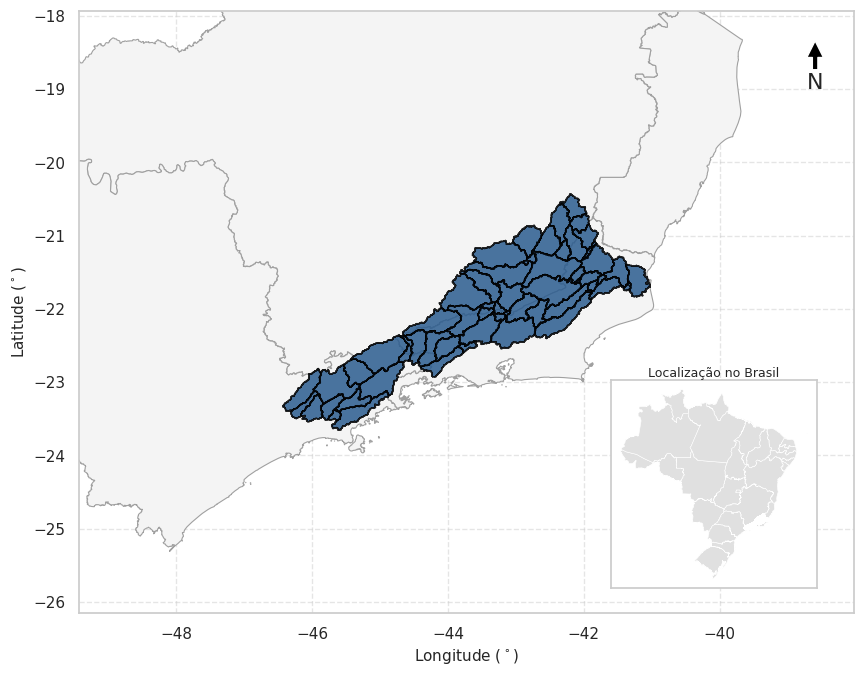

In [9]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt

output_dir = "/home/vinicius/projects/projects/gee-data-pipeline/saidas/graphs"
os.makedirs(output_dir, exist_ok=True)

# 1. Carregar estados do Brasil diretamente de repositório GeoJSON público
url_geojson = "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson"
gdf_brasil = gpd.read_file(url_geojson)
gdf_brasil = gdf_brasil.to_crs(epsg=4326)

# 2. Carregar o GeoDataFrame da BHRPS (substitua 'gdf' pela sua variável de sub-bacias)
gdf_bhrps = gdf.to_crs(epsg=4326)

# --- FIGURA PRINCIPAL E SUBPLOTS ---
fig, ax_main = plt.subplots(figsize=(10, 8))

# A. MAPA PRINCIPAL: Região Sudeste e BHRPS
sudeste_siglas = ["MG", "ES", "RJ", "SP"]
gdf_sudeste = gdf_brasil[gdf_brasil["sigla"].isin(sudeste_siglas)]

# Plotar os estados do Sudeste
gdf_sudeste.plot(
    ax=ax_main, facecolor="#f4f4f4", edgecolor="#a0a0a0", linewidth=0.8
)

# Plotar a BHRPS em destaque
gdf_bhrps.plot(
    ax=ax_main,
    facecolor="#2b5c8f",
    edgecolor="black",
    linewidth=1,
    alpha=0.85,
    label="BHRPS",
)

# Ajustar limites do zoom na BHRPS + vizinhança
minx, miny, maxx, maxy = gdf_bhrps.total_bounds
ax_main.set_xlim(minx - 3.0, maxx + 3.0)
ax_main.set_ylim(miny - 2.5, maxy + 2.5)

ax_main.set_xlabel(r"Longitude ($^\circ$)", fontsize=11)
ax_main.set_ylabel(r"Latitude ($^\circ$)", fontsize=11)
ax_main.grid(True, linestyle="--", alpha=0.5)

# Indicação do Norte (canto superior direito)
ax_main.annotate(
    "N",
    xy=(0.95, 0.95),
    xytext=(0.95, 0.88),
    arrowprops=dict(facecolor="black", width=4, headwidth=12),
    ha="center",
    va="center",
    fontsize=16,
    xycoords=ax_main.transAxes,
)

# B. MAPA DE ENCARTE (INSET): Posicionado no canto INFERIOR DIREITO
# Parâmetros: [esquerda, baixo, largura, altura] em fração da figura (0 a 1)
ax_inset = fig.add_axes([0.63, 0.15, 0.26, 0.26])

# Plotar o Brasil completo no encarte
gdf_brasil.plot(
    ax=ax_inset, facecolor="#e0e0e0", edgecolor="#ffffff", linewidth=0.4
)

# Destacar a BHRPS no mapa do Brasil
gdf_bhrps.plot(ax=ax_inset, color="red", markersize=10)

ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax_inset.set_title("Localização no Brasil", fontsize=9, pad=2)

# --- SALVAR O RESULTADO ---
caminho_salvamento = os.path.join(output_dir, "mapa_localizacao_bhrps.png")
plt.savefig(caminho_salvamento, dpi=300, bbox_inches="tight")

plt.show()